# GRU — análisis de errores en test

Análisis **post hoc y descriptivo** de los errores de la evaluación en test (`03_evaluacion_test.ipynb`). No entrena, no predice y no cambia umbrales ni resultados: usa las probabilidades de test ya guardadas y el `umbral_f2` de validación de cada semilla. **No se toma ninguna decisión del modelo con este análisis.**

- **Modelo principal:** `aleatorio_w10`. **Contraste:** `w1`.
- **Error persistente:** el que se repite en al menos 3 de las 5 semillas.

## 1. Configuración y carga

In [1]:
import sys
sys.path.append("../..")  # raíz del repo, para poder importar src.*

import json
import os

import numpy as np
import pandas as pd
from IPython.display import display

from src.models.gru.evaluation import plot_barras_por_minuto
from src.preprocessing.clean import cargar_dataset_limpio

In [2]:
SEMILLAS = [0, 1, 2, 3, 4]
MIN_SEMILLAS = 3  # un error es persistente si ocurre en al menos estas semillas
assert 2 * MIN_SEMILLAS > len(SEMILLAS)

DATA_DIR = "../../data/sequences"
PROCESSED_PATH = "../../data/processed/wednesday_low_and_slow_clean.csv"
TEST_DIR = "../../results/gru/03_evaluacion_test"
RESULTS_DIR = "../../results/gru/04_analisis_errores"
os.makedirs(RESULTS_DIR, exist_ok=True)

PRINCIPAL, CONTRASTE = "aleatorio_w10", "w1"
SEEDS_PATHS = {
    "aleatorio_w10": "../../results/gru/02_ablaciones/aleatorio_w10_seeds.json",
    "w1": "../../results/gru/02_ablaciones/w1_seeds.json",
}
NOMBRES_MODELO = {
    "aleatorio_w10": "GRU W=10 (orden aleatorio)",
    "w1": "GRU W=1",
}
NOMBRES_TIPO = {"DoS slowloris": "Slowloris", "DoS Slowhttptest": "Slowhttptest"}
FEATURES_PERFIL = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Fwd Packet Length Mean",
    "Flow IAT Mean", "Flow Bytes/s", "Init_Win_bytes_forward", "Init_Win_bytes_backward",
]

# Umbral de cada (modelo, semilla): el umbral_f2 elegido en validación, igual que en 03
UMBRALES = {}
for nombre, seeds_path in SEEDS_PATHS.items():
    with open(seeds_path, encoding="utf-8") as f:
        seeds = json.load(f)
    assert seeds["conjunto"] == "validacion" and seeds["semillas"] == SEMILLAS, nombre
    UMBRALES[nombre] = {fila["semilla"]: fila["umbral_f2"] for fila in seeds["por_semilla"]}

In [3]:
idx_comun = np.load(f"{TEST_DIR}/idx_test_comun.npy")

# Mismo orden e índice que usa train_test_split_by_flow(desempate="csv")
df = cargar_dataset_limpio(PROCESSED_PATH)
df = df.sort_values("Timestamp", kind="stable").reset_index(drop=True)
test = df.loc[idx_comun, ["Timestamp", "Label", "label_binaria"] + FEATURES_PERFIL].reset_index(drop=True)
del df

y_secuencias = pd.Series(
    np.load(f"{DATA_DIR}/y_test_w10.npy"), index=np.load(f"{DATA_DIR}/idx_test_w10.npy"),
)
assert np.array_equal(test["label_binaria"].to_numpy(), y_secuencias.loc[idx_comun].to_numpy()), (
    "Los índices no corresponden al CSV procesado actual"
)
es_ataque = test["label_binaria"].to_numpy() == 1

# PRED[modelo]: matriz (semillas, filas) con la predicción de ataque de cada semilla
PRED = {
    nombre: np.array([
        np.load(f"{TEST_DIR}/{nombre}_seed{seed}_test_proba.npy") >= UMBRALES[nombre][seed]
        for seed in SEMILLAS
    ])
    for nombre in (PRINCIPAL, CONTRASTE)
}

# Los errores deben ser exactamente los que reportó 03
with open(f"{TEST_DIR}/test_resultados.json", encoding="utf-8") as f:
    referencia = json.load(f)
for fila in referencia["por_semilla"]:
    if fila["modelo"] in PRED:
        pred = PRED[fila["modelo"]][SEMILLAS.index(fila["semilla"])]
        fn, fp = int((es_ataque & ~pred).sum()), int((~es_ataque & pred).sum())
        assert (fn, fp) == (fila["fn"], fila["fp"]), (
            f"{fila['modelo']} semilla {fila['semilla']}: FN/FP {fn}/{fp} != {fila['fn']}/{fila['fp']} de 03"
        )

print(f"Filas de test: {len(test)} | ataques: {int(es_ataque.sum())} | benignos: {int((~es_ataque).sum())}")
print("OK: FN y FP por semilla coinciden con test_resultados.json")

Filas de test: 66454 | ataques: 1164 | benignos: 65290
OK: FN y FP por semilla coinciden con test_resultados.json


## 2. Errores persistentes

Por fila se cuenta en cuántas semillas ocurre el error. **FN persistente:** ataque no detectado en al menos 3 de 5 semillas. **FP persistente:** benigno marcado como ataque en al menos 3 de 5.

In [4]:
# Número de semillas en las que cada fila es FN o FP
SEMILLAS_FN = {nombre: np.where(es_ataque, (~pred).sum(axis=0), 0) for nombre, pred in PRED.items()}
SEMILLAS_FP = {nombre: np.where(~es_ataque, pred.sum(axis=0), 0) for nombre, pred in PRED.items()}
FN_PERSISTENTE = {nombre: n >= MIN_SEMILLAS for nombre, n in SEMILLAS_FN.items()}
FP_PERSISTENTE = {nombre: n >= MIN_SEMILLAS for nombre, n in SEMILLAS_FP.items()}

filas = []
for nombre in PRED:
    for error, n_semillas, n_clase in (
        ("FN", SEMILLAS_FN[nombre], int(es_ataque.sum())),
        ("FP", SEMILLAS_FP[nombre], int((~es_ataque).sum())),
    ):
        filas.append({
            "modelo": NOMBRES_MODELO[nombre],
            "error": error,
            "filas_de_la_clase": n_clase,
            "en_alguna_semilla": int((n_semillas >= 1).sum()),
            "solo_en_una_semilla": int((n_semillas == 1).sum()),
            "persistentes": int((n_semillas >= MIN_SEMILLAS).sum()),
            "en_las_5_semillas": int((n_semillas == len(SEMILLAS)).sum()),
        })

tabla_persistentes = pd.DataFrame(filas).set_index(["modelo", "error"])
tabla_persistentes.to_csv(f"{RESULTS_DIR}/errores_persistentes.csv")
tabla_persistentes

filas_de_la_clase  en_alguna_semilla  \
modelo                     error                                         
GRU W=10 (orden aleatorio) FN                  1164                 59   
                           FP                 65290                252   
GRU W=1                    FN                  1164                212   
                           FP                 65290                145   

                                  solo_en_una_semilla  persistentes  \
modelo                     error                                      
GRU W=10 (orden aleatorio) FN                      24            27   
                           FP                     101           115   
GRU W=1                    FN                     203             8   
                           FP                      66            50   

                                  en_las_5_semillas  
modelo                     error                     
GRU W=10 (orden aleatorio) FN                    17  
                           FP                    49  
GRU W=1                    FN                     8  
                           FP                    11

## 3. Falsos negativos del modelo principal

Por tipo de ataque, por minuto y por posición dentro del tramo de ataque en test. La posición divide en tres tercios iguales el tiempo entre el primer y el último ataque de cada tipo en test (el `Timestamp` tiene resolución de un minuto). `fn_media_por_semilla` es el promedio de FN entre las 5 semillas, sin exigir persistencia.

In [5]:
def resumir(filas, columnas, prefijo):
    grupos = filas.groupby(columnas, observed=True)
    resumen = pd.DataFrame({
        "filas": grupos.size(),
        f"{prefijo}_persistentes": grupos["persistente"].sum(),
        f"{prefijo}_media_por_semilla": grupos["semillas_con_error"].sum() / len(SEMILLAS),
    })
    resumen[f"pct_{prefijo}_persistentes"] = 100 * resumen[f"{prefijo}_persistentes"] / resumen["filas"]
    return resumen


ataques = test.loc[es_ataque, ["Timestamp"]].assign(
    **{"tipo de ataque": test.loc[es_ataque, "Label"].map(NOMBRES_TIPO)},
    persistente=FN_PERSISTENTE[PRINCIPAL][es_ataque],
    semillas_con_error=SEMILLAS_FN[PRINCIPAL][es_ataque],
)
inicio = ataques.groupby("tipo de ataque")["Timestamp"].transform("min")
fin = ataques.groupby("tipo de ataque")["Timestamp"].transform("max")
ataques["posicion"] = pd.cut(
    (ataques["Timestamp"] - inicio) / (fin - inicio),
    bins=[-0.001, 1 / 3, 2 / 3, 1.0], labels=["inicio", "medio", "final"],
)

fn_por_tipo = resumir(ataques, "tipo de ataque", "fn")
fn_por_minuto = resumir(ataques, ["Timestamp", "tipo de ataque"], "fn")
fn_por_posicion = resumir(ataques, ["tipo de ataque", "posicion"], "fn")
minutos = ataques.groupby(["tipo de ataque", "posicion"], observed=True)["Timestamp"]
fn_por_posicion.insert(0, "desde", minutos.min().dt.strftime("%H:%M"))
fn_por_posicion.insert(1, "hasta", minutos.max().dt.strftime("%H:%M"))

fn_por_tipo.to_csv(f"{RESULTS_DIR}/fn_por_tipo.csv")
fn_por_minuto.to_csv(f"{RESULTS_DIR}/fn_por_minuto.csv")
fn_por_posicion.to_csv(f"{RESULTS_DIR}/fn_por_posicion.csv")

display(fn_por_tipo, fn_por_posicion, fn_por_minuto)

,filas,fn_persistentes,fn_media_por_semilla,pct_fn_persistentes
tipo de ataque,,,,
Slowhttptest,250,21,21.4,8.400000
Slowloris,914,6,10.4,0.656455


desde  hasta  filas  fn_persistentes  \
tipo de ataque posicion                                         
Slowhttptest   inicio    10:33  10:34     98                3   
               medio     10:35  10:35     24                2   
               final     10:36  10:37    128               16   
Slowloris      inicio    10:07  10:08    479                0   
               medio     10:09  10:09    262                0   
               final     10:10  10:11    173                6   

                         fn_media_por_semilla  pct_fn_persistentes  
tipo de ataque posicion                                             
Slowhttptest   inicio                     5.4             3.061224  
               medio                      2.2             8.333333  
               final                     13.8            12.500000  
Slowloris      inicio                     0.0             0.000000  
               medio                      0.0             0.000000  
               final                     10.4             3.468208

,,filas,fn_persistentes,fn_media_por_semilla,pct_fn_persistentes
Timestamp,tipo de ataque,,,,
2017-07-05 10:07:00,Slowloris,207,0,0.0,0.000000
2017-07-05 10:08:00,Slowloris,272,0,0.0,0.000000
2017-07-05 10:09:00,Slowloris,262,0,0.0,0.000000
2017-07-05 10:10:00,Slowloris,171,6,10.0,3.508772
2017-07-05 10:11:00,Slowloris,2,0,0.4,0.000000
2017-07-05 10:33:00,Slowhttptest,61,0,2.0,0.000000
2017-07-05 10:34:00,Slowhttptest,37,3,3.4,8.108108
2017-07-05 10:35:00,Slowhttptest,24,2,2.2,8.333333
2017-07-05 10:36:00,Slowhttptest,1,0,0.0,0.000000


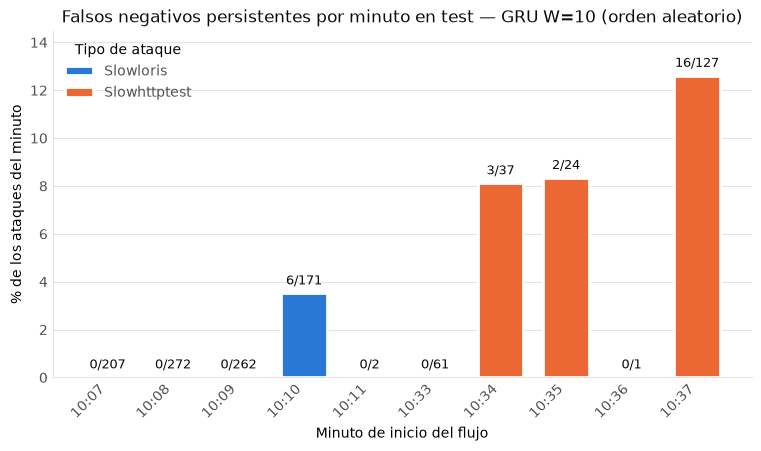

In [6]:
fn_figura = fn_por_minuto.reset_index("tipo de ataque")
fn_figura["fn/ataques"] = [f"{fn}/{n}" for fn, n in zip(fn_figura["fn_persistentes"], fn_figura["filas"])]

fig = plot_barras_por_minuto(
    fn_figura, valor="pct_fn_persistentes", grupo="tipo de ataque", anotacion="fn/ataques",
    titulo=f"Falsos negativos persistentes por minuto en test — {NOMBRES_MODELO[PRINCIPAL]}",
    etiqueta_y="% de los ataques del minuto",
    save_path=f"{RESULTS_DIR}/fn_por_minuto.png",
)

## 4. Falsos positivos del modelo principal

Por minuto, separando los minutos en los que hay ataques en test de los minutos sin ataques.

In [7]:
minutos_con_ataques = set(test.loc[es_ataque, "Timestamp"])
benignos = test.loc[~es_ataque, ["Timestamp"]].assign(
    persistente=FP_PERSISTENTE[PRINCIPAL][~es_ataque],
    semillas_con_error=SEMILLAS_FP[PRINCIPAL][~es_ataque],
)
benignos["tipo de minuto"] = np.where(
    benignos["Timestamp"].isin(minutos_con_ataques), "con ataques", "sin ataques",
)

fp_por_tipo_de_minuto = resumir(benignos, "tipo de minuto", "fp")
fp_por_tipo_de_minuto.insert(0, "minutos", benignos.groupby("tipo de minuto")["Timestamp"].nunique())
fp_por_minuto = resumir(benignos, ["Timestamp", "tipo de minuto"], "fp")

fp_por_tipo_de_minuto.to_csv(f"{RESULTS_DIR}/fp_por_tipo_de_minuto.csv")
fp_por_minuto.to_csv(f"{RESULTS_DIR}/fp_por_minuto.csv")

display(fp_por_tipo_de_minuto, fp_por_minuto[fp_por_minuto["fp_persistentes"] > 0])

,minutos,filas,fp_persistentes,fp_media_por_semilla,pct_fp_persistentes
tipo de minuto,,,,,
con ataques,10,8336,77,89.4,0.923704
sin ataques,82,56954,38,41.8,0.066721


,,filas,fp_persistentes,fp_media_por_semilla,pct_fp_persistentes
Timestamp,tipo de minuto,,,,
2017-07-05 09:39:00,sin ataques,709,2,1.6,0.282087
2017-07-05 09:45:00,sin ataques,1131,2,3.0,0.176835
2017-07-05 10:07:00,con ataques,1626,2,4.0,0.123001
2017-07-05 10:08:00,con ataques,556,39,42.2,7.014388
2017-07-05 10:09:00,con ataques,365,7,11.2,1.917808
2017-07-05 10:34:00,con ataques,805,13,14.0,1.614907
2017-07-05 10:35:00,con ataques,618,9,9.4,1.456311
2017-07-05 10:36:00,con ataques,1343,2,2.0,0.148920
2017-07-05 10:37:00,con ataques,1281,5,5.4,0.390320


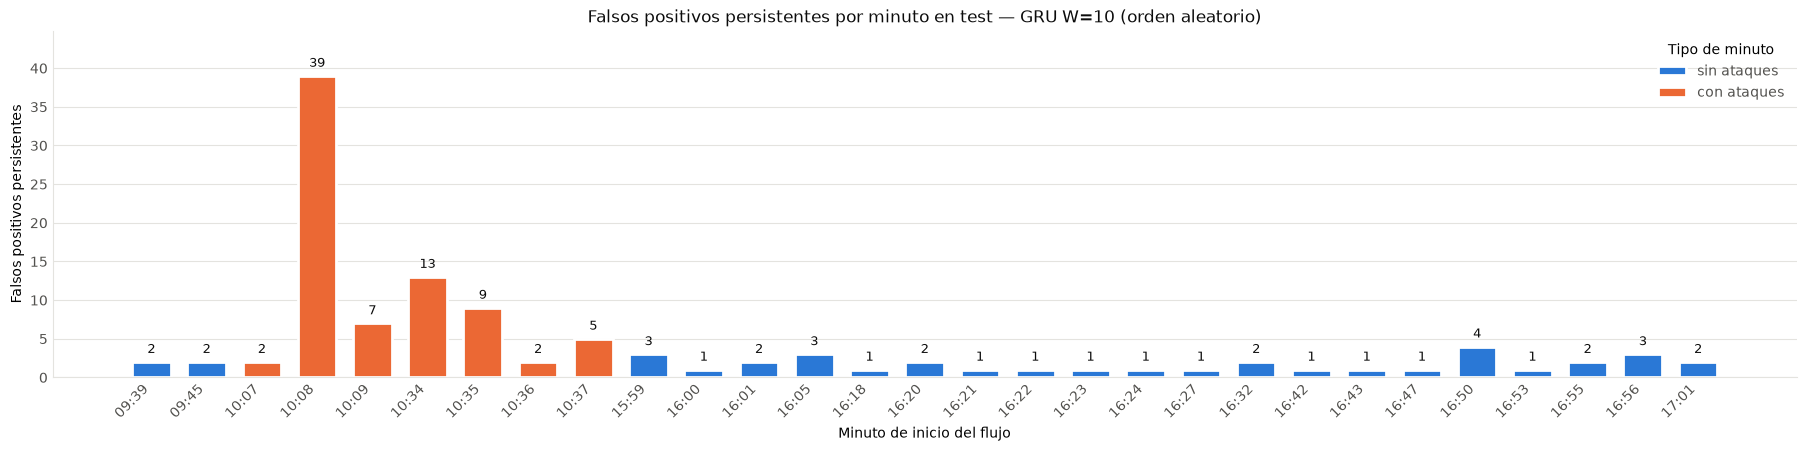

In [8]:
fp_figura = fp_por_minuto[fp_por_minuto["fp_persistentes"] > 0].reset_index("tipo de minuto")

if fp_figura.empty:
    print("No hay falsos positivos persistentes: no se genera la figura.")
else:
    fig = plot_barras_por_minuto(
        fp_figura, valor="fp_persistentes", grupo="tipo de minuto", anotacion="fp_persistentes",
        titulo=f"Falsos positivos persistentes por minuto en test — {NOMBRES_MODELO[PRINCIPAL]}",
        etiqueta_y="Falsos positivos persistentes",
        save_path=f"{RESULTS_DIR}/fp_por_minuto.png",
    )

## 5. Perfil de features por tipo de resultado

Mediana de cada feature, en sus valores originales del CSV (sin escalar), para TP, FN, FP y TN del modelo principal. Cada fila se clasifica por la predicción mayoritaria de las 5 semillas, de modo que FN y FP son los errores persistentes de la sección 2.

In [9]:
detectado = PRED[PRINCIPAL].sum(axis=0) >= MIN_SEMILLAS
resultado = np.select(
    [es_ataque & detectado, es_ataque & ~detectado, ~es_ataque & detectado],
    ["TP", "FN", "FP"], default="TN",
)
assert np.array_equal(resultado == "FN", FN_PERSISTENTE[PRINCIPAL])
assert np.array_equal(resultado == "FP", FP_PERSISTENTE[PRINCIPAL])

orden = ["TP", "FN", "FP", "TN"]
perfil = test[FEATURES_PERFIL].groupby(resultado).median().reindex(orden)
perfil.insert(0, "filas", pd.Series(resultado).value_counts().reindex(orden, fill_value=0))
perfil = perfil.rename_axis("resultado")

perfil.to_csv(f"{RESULTS_DIR}/perfil_features.csv")
perfil

,filas,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packet Length Mean,Flow IAT Mean,Flow Bytes/s,Init_Win_bytes_forward,Init_Win_bytes_backward
resultado,,,,,,,,,
TP,1137,8537923.0,2.0,1.0,8.0,1710425.417,2.457789e+01,235.0,235.0
FN,27,192.0,1.0,2.0,1448.0,96.000,1.030000e+07,235.0,235.0
FP,115,1667990.0,2.0,0.0,31.0,1635986.000,3.789763e+01,395.0,-1.0
TN,65175,30961.0,2.0,2.0,37.0,12144.200,5.070568e+03,0.0,-1.0


## 6. Coincidencia de errores entre modelos

Errores persistentes del modelo principal y del contraste sobre las mismas filas: cuántos comparten y cuántos son exclusivos de cada uno.

In [10]:
filas = []
for error, persistente in (("FN", FN_PERSISTENTE), ("FP", FP_PERSISTENTE)):
    a, b = persistente[PRINCIPAL], persistente[CONTRASTE]
    filas.append({
        "error": error,
        "en ambos": int((a & b).sum()),
        f"solo {NOMBRES_MODELO[PRINCIPAL]}": int((a & ~b).sum()),
        f"solo {NOMBRES_MODELO[CONTRASTE]}": int((~a & b).sum()),
    })

coincidencia = pd.DataFrame(filas).set_index("error")
coincidencia.to_csv(f"{RESULTS_DIR}/coincidencia_errores.csv")
coincidencia

,en ambos,solo GRU W=10 (orden aleatorio),solo GRU W=1
error,,,
FN,8,19,0
FP,32,83,18


## Conclusiones


- Los FN y FP por semilla coinciden con los de `03_evaluacion_test.ipynb`. Se considera persistente un error que ocurre en al menos 3 de las 5 semillas.
- **Persistencia:** el modelo principal (GRU W=10, orden aleatorio) tiene 27 FN persistentes (17 en las 5 semillas) y 115 FP persistentes (49 en las 5). En GRU W=1 los errores dependen más de la semilla: de 212 ataques no detectados en alguna semilla, 203 lo son en una sola (coincide con los 212 FN de la semilla 4), y solo 8 son persistentes. Tiene 50 FP persistentes.
- **FN por tipo de ataque:** 21 de los 27 FN persistentes son Slowhttptest (8.4 % de sus 250 ataques), frente a 6 de slowloris (0.7 % de 914).
- **FN por posición:** se concentran en el tramo final de cada ataque. Los 6 de slowloris están en 10:10 y 16 de los 21 de Slowhttptest en 10:37. En el inicio de slowloris (10:07–10:08) no hay ningún FN persistente.
- **Perfil de los FN:** no tienen el perfil lento de los ataques detectados. La duración mediana es de 192 µs, frente a 8.5 s en los TP; el Fwd Packet Length Mean, de 1,448 bytes frente a 8; y Flow Bytes/s, de 1.0·10⁷ frente a 25. Son flujos cortos con un paquete de tamaño completo, que por sus features no se distinguen del tráfico normal.
- **FP por minuto:** 77 de los 115 FP persistentes ocurren en los 10 minutos con ataques, donde afectan al 0.92 % de los flujos benignos, frente al 0.067 % en los 82 minutos sin ataques. El máximo es 10:08, con 39 FP (7.0 % de los benignos de ese minuto).
- **Perfil de los FP:** duración mediana de 1.7 s, Flow IAT Mean de 1.6 s y ningún paquete de respuesta (mediana de Total Backward Packets = 0). Se parecen más a los ataques detectados que al tráfico benigno típico (duración mediana de 31 ms). El dataset procesado no incluye IPs, por lo que no se puede comprobar si van dirigidos al servidor atacado.
- **Coincidencia con GRU W=1:** los 8 FN persistentes de W=1 también son FN del modelo principal, que tiene 19 adicionales. En FP, 32 son comunes, 83 exclusivos del modelo principal y 18 exclusivos de W=1. Con orden aleatorio, la ventana agrega errores a los del flujo individual.
- **Patrón por minuto (descriptivo):** en los minutos donde los ataques son una fracción alta de las filas de test (10:08 y 10:09, con 33 % y 42 %) no hay FN persistentes y se concentran FP. Donde son una fracción baja (10:34, 10:35 y 10:37, entre 4 % y 9 %) se concentran los FN de Slowhttptest. Es consistente con que la ventana con orden aleatorio aporte sobre todo la proporción de ataques del minuto, pero este análisis no lo comprueba.